# Residual Analysis: Multiple Energy Bins

This notebook demonstrates the two ways to use `ResidualAnalysis` when the observed and expected histograms contain multiple measured-energy (`Em`) bins:

1. Preserve every original `Em` bin to study energy-resolved CDS residuals.
2. Select an interval with `select_energy_range(energy_min, energy_max)` and aggregate its bins before calculating standard CDS residuals.

Both workflows start from the same analysis object and use the same masked observed and expected counts. Selecting an interval returns a new object and does not modify the original multi-energy analysis.

> **Important data-provenance note:** This notebook uses an artificial multi-energy demonstration product derived from the stored DC4 511 keV residual product. Its embedded metadata records `product_type=artificial_multienergy_test`, the DC4 source file, a random seed, energy edges, and scale-factor arrays. The repository does not provide an independent fitted multi-energy residual product for this tutorial.
>
> The fixture is used because its explicit `Em` dimension can demonstrate energy-resolved projections, `energy_bin_index` map selection, and multi-bin aggregation with `select_energy_range()`. These residuals test and illustrate the class interface; they must not be interpreted as scientific evidence for the quality of an independent multi-energy fit.

## Navigation

| Section | Contents |
|---|---|
| [Part I: Complete practical workflows](#part-i) | Run the energy-resolved and selected-energy-range workflows. |
| [Energy-range selection](#energy-range-selection) | Choose existing `Em` edges, aggregate bins, and verify the returned interval. |
| [Part II: API reference and advanced options](#part-ii) | Method documentation, parameters, restrictions, and customization. |
| [Using your own data](#using-your-own-data) | Replace the demonstration file and histogram objects safely. |
| [Available projections and residual types](#projections-and-residuals) | Explore energy-resolved and energy-integrated products. |
| [Plotting customization and slice selection](#plotting-customization) | Configure plotting options plus Phi- and energy-bin indices. |
| [Poisson Monte Carlo references](#poisson-monte-carlo) | Generate reproducible fixed-fit Pearson references. |
| [Statistical diagnostics](#statistical-diagnostics) | Summarize the selected energy interval. |

<a id="part-i"></a>

# PART I: Complete practical workflows

This part contains two uninterrupted normal-use workflows: first, residuals that preserve every original `Em` bin; second, standard angular residuals for an aggregated energy interval. Detailed API exploration begins only in Part II.

## Setup

The following cells locate the `workflow` directory and import the histogram, residual-analysis, plotting, and display tools used in this notebook.

In [1]:
%load_ext autoreload
%autoreload 2

# Handle filesystem paths in a platform-independent way.
from pathlib import Path
import sys

working_dir = Path.cwd()
repo_root = (
    working_dir.parent
    if working_dir.name == "notebooks"
    else working_dir
)

# Make the local workflow modules importable.
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals

from histpy import Histogram
from IPython.display import display
import h5py
import numpy as np

## Load the residual products

`ResidualAnalysis` requires an observed-count histogram and the corresponding fitted expected-count histogram. The two histograms must have identical axes and shapes, and their counts must be finite and non-negative.

This notebook uses `workflow/data/residual/test_multienergy_residual_products.hdf5`. Embedded metadata identifies it as an `artificial_multienergy_test` derived from `03_511_imaging_residual_products.hdf5`, with a recorded random seed and energy-dependent scale factors. The repository does not contain a separate multi-energy fit that produced this file, so it must be treated as a demonstration/simulation fixture rather than a genuine fitted multi-energy DC4 result.

To analyze another product, change `residual_file` and, if necessary, the `name` values used to load `observed` and `expected`. HDF5 object names can differ, so inspect them before calling `Histogram.open()`.

In [3]:
# Locate the multi-energy residual product.
residual_dir = repo_root / "data" / "residual"
residual_file = residual_dir / "test_multienergy_residual_products.hdf5"

print("Input file:", residual_file)
print("File exists:", residual_file.exists())

Input file: /Users/maura/Documents/COSI/data-challenge-4/workflow/data/residual/test_multienergy_residual_products.hdf5
File exists: True


In [4]:
# Inspect the available objects before choosing histogram names.
with h5py.File(residual_file, "r") as residual_data:
    available_objects = list(residual_data.keys())

print("Available objects:", available_objects)

Available objects: ['background_expectation', 'observed', 'simulation_metadata', 'source_expectation', 'total_expectation']


### Confirm the product provenance

Always inspect provenance before interpreting residuals. This tutorial file is deliberately marked as an artificial multi-energy test product. The following cell reads both its attributes and stored metadata arrays; these describe the fixture and are not a fitted multi-energy result.

In [5]:
# Read all provenance recorded with the existing tutorial fixture.
with h5py.File(residual_file, "r") as residual_data:
    metadata_group = residual_data["simulation_metadata"]
    simulation_metadata = dict(metadata_group.attrs)
    simulation_metadata_arrays = {
        name: metadata_group[name][()]
        for name in metadata_group.keys()
    }

display(simulation_metadata)
display(simulation_metadata_arrays)

{'product_type': 'artificial_multienergy_test',
 'random_seed': np.int64(20261014),
 'source_energy_bin_keV': array([509., 513.]),
 'source_file': '/Users/maura/Documents/COSI/data-challenge-4/workflow/data/residual/03_511_imaging_residual_products.hdf5'}

{'background_scale_factors': array([0.8, 1.2, 0.9]),
 'energy_bin_edges_keV': array([300., 400., 600., 800.]),
 'source_scale_factors': array([0.6 , 1.  , 0.45])}

In [6]:
# Load the observed counts and total fitted expectation.
# Replace these names if the previous cell reports different objects.
observed = Histogram.open(
    residual_file,
    name="observed",
)

expected = Histogram.open(
    residual_file,
    name="total_expectation",
)

## Verify the input structure

Inspect both histograms before initializing the analysis. This example must report more than one `Em` bin. If a file reports one bin, no energy selection is required; use the single-bin tutorial instead.

The printed `Em` edges are also the only valid limits for `select_energy_range()`.

In [7]:
# Confirm that both histograms have matching dimensions.
energy_bin_count = observed.axes["Em"].nbins
energy_edges = observed.axes["Em"].edges
energy_edges_keV = energy_edges.to_value("keV")

print("Observed axes:", observed.axes.labels)
print("Expected axes:", expected.axes.labels)
print("Observed shape:", observed.shape)
print("Expected shape:", expected.shape)
print("Number of Em bins:", energy_bin_count)
print("Available Em edges:", energy_edges)
print("Indexed Em edges:")
for edge_index, edge_keV in enumerate(energy_edges_keV):
    print(f"  edge {edge_index}: {edge_keV:g} keV")

if energy_bin_count <= 1:
    raise ValueError(
        "This tutorial requires an input containing multiple Em bins."
    )

Observed axes: ['Em' 'Phi' 'PsiChi']
Expected axes: ['Em' 'Phi' 'PsiChi']
Observed shape: (3, 60, 3072)
Expected shape: (3, 60, 3072)
Number of Em bins: 3
Available Em edges: [300. 400. 600. 800.] keV
Indexed Em edges:
  edge 0: 300 keV
  edge 1: 400 keV
  edge 2: 600 keV
  edge 3: 800 keV


## Initialize the full multi-energy analysis

Initialize one `ResidualAnalysis` object from the complete matching histograms. No energy bins are selected or combined at this stage, so `full_analysis` preserves the original `Em` axis.

In [8]:
# Preserve every original Em bin during initialization.
# Add expected_floor=<known value> only when the model uses such a floor.
full_analysis = ResidualAnalysis(
    observed,
    expected,
)

## Workflow A: Preserve the original energy bins

The loaded file contains multiple `Em` bins, so the first workflow preserves energy. It shows the energy spectrum, an energy-versus-`Phi` residual map, and one energy slice of the `PsiChi` HEALPix residual cube:

1. Calculate an energy-resolved residual histogram.
2. Initialize `PlottingResiduals` with the full analysis.
3. Plot representative energy-resolved projections.

The example uses raw residuals and therefore requires no Poisson simulations. The direct `Em-Phi` residual variable is available for numerical work; `plot()` obtains its own projected residuals from `full_analysis`. `energy_bin_index` selects only the displayed HEALPix slice and does not remove or aggregate any bin.

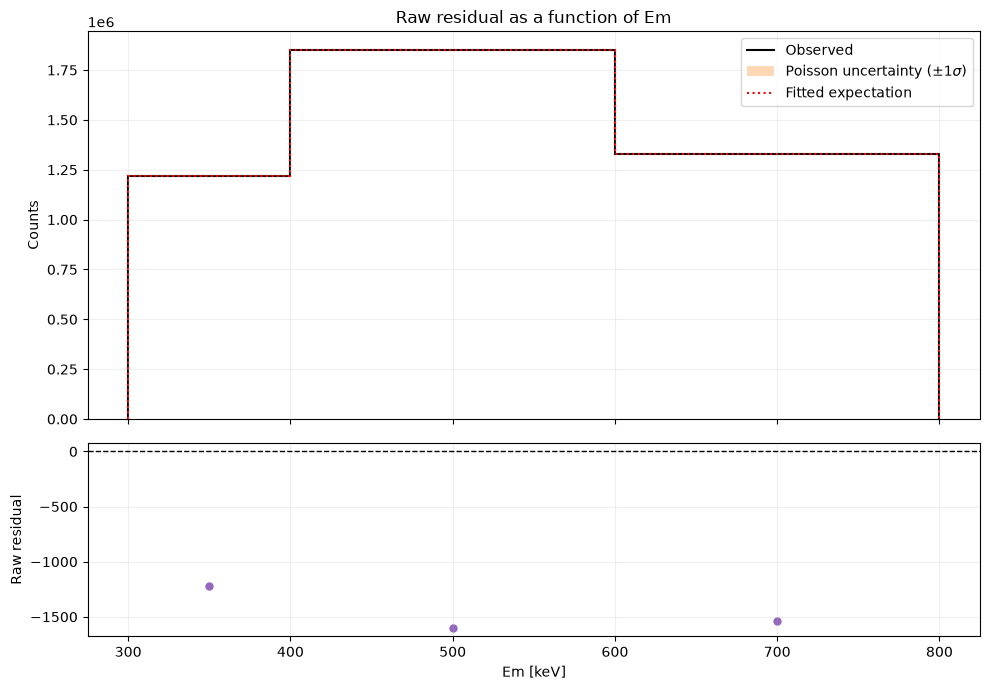

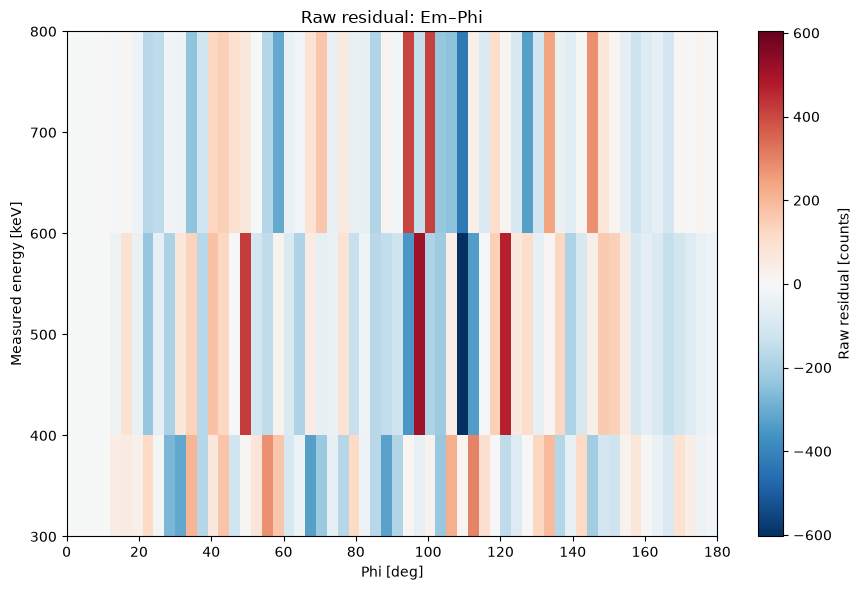

Displayed HEALPix energy interval: 300.0 keV to 400.0 keV


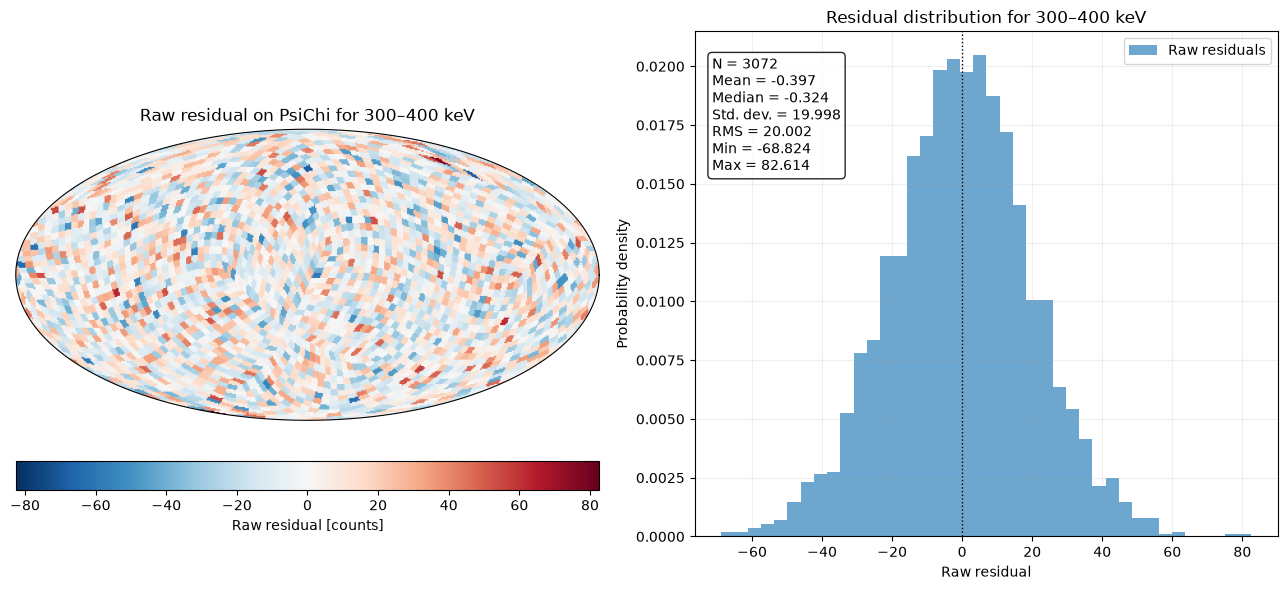

Residual axes: ['Em' 'Phi']
Residual shape: (3, 60)


In [9]:
# Calculate one energy-resolved residual histogram.
standard_em_phi_residual = full_analysis.residual_function(
    "Em_Phi_projection",
    residual_type="raw",
)

# Initialize the plotting interface from the same analysis object.
standard_energy_plotter = PlottingResiduals(full_analysis)

# Show total observed and expected counts versus measured energy.
standard_em_figure = standard_energy_plotter.plot(
    "Em_projection",
    residual_type="raw",
)

# Show residuals versus energy and Phi while preserving every Em bin.
standard_em_phi_figure = standard_energy_plotter.plot(
    "Em_Phi_projection",
    residual_type="raw",
)

# Modify this zero-based variable to display another original energy bin.
energy_bin_index = 0
if not 0 <= energy_bin_index < energy_bin_count:
    raise IndexError("energy_bin_index is outside the available Em bins.")

print(
    "Displayed HEALPix energy interval:",
    energy_edges[energy_bin_index],
    "to",
    energy_edges[energy_bin_index + 1],
)
standard_em_psichi_figure = standard_energy_plotter.plot(
    "Em_PsiChi_projection",
    residual_type="raw",
    energy_bin_index=energy_bin_index,
)

print("Residual axes:", standard_em_phi_residual.axes.labels)
print("Residual shape:", standard_em_phi_residual.shape)

### Multi-energy workflow output

`Em_projection` reveals whether total count discrepancies vary with energy. `standard_em_phi_residual` retains both `Em` and `Phi`, so its rectangular map reveals energy-dependent angular structure. The sliced HEALPix map reveals localized `PsiChi` structure within the displayed original energy bin. All three views come from `full_analysis`; no energy bin was removed or aggregated.

<a id="energy-range-selection"></a>

## Workflow B: Select and aggregate an energy interval

When the goal is one combined energy band, `select_energy_range()` requires limits that coincide with existing `Em` edges. Rather than typing energies independently, choose two indices from the indexed edge list printed above. The lower index identifies `energy_min`; the upper index identifies `energy_max`; every original bin between those edges is aggregated into one.

In the next cell, **`lower_edge_index` and `upper_edge_index` are the only variables users need to modify**. The current values select edges 0 and 2, which combine the first two original energy bins. The returned one-bin analysis supports the standard CDS residual projections.

In [10]:
# Modify only these two edge indices to select another interval.
lower_edge_index = 0
upper_edge_index = 2

if not 0 <= lower_edge_index < upper_edge_index < len(energy_edges_keV):
    raise IndexError("Choose ordered edge indices from the printed edge list.")

# Convert the selected existing edges to the numeric keV arguments.
energy_min = float(energy_edges_keV[lower_edge_index])
energy_max = float(energy_edges_keV[upper_edge_index])
selected_original_bins = [
    (energy_edges[index], energy_edges[index + 1])
    for index in range(lower_edge_index, upper_edge_index)
]

print("Original bins to aggregate:")
for bin_index, interval in enumerate(
    selected_original_bins, start=lower_edge_index
):
    print(f"  bin {bin_index}: {interval[0]} to {interval[1]}")

Original bins to aggregate:
  bin 0: 300.0 keV to 400.0 keV
  bin 1: 400.0 keV to 600.0 keV


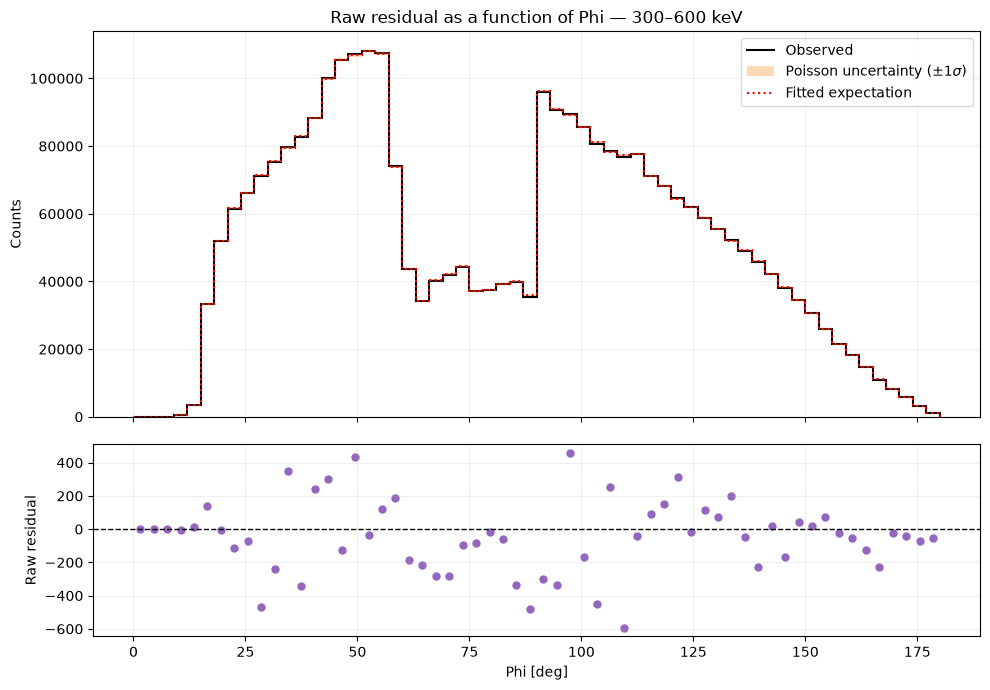

/Users/maura/Documents/COSI/data-challenge-4/workflow/src/plot_residuals.py:1086: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout()


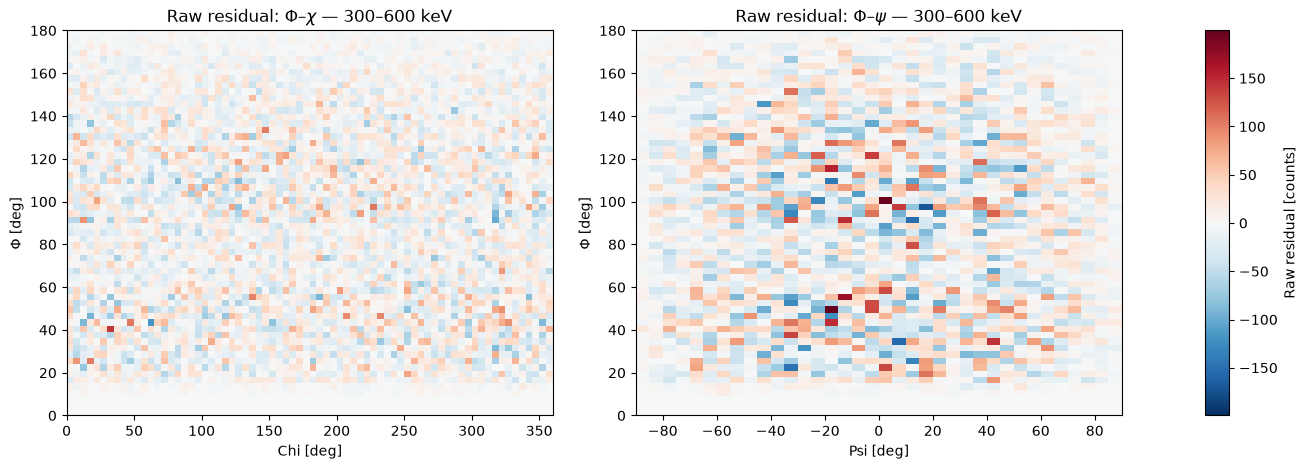

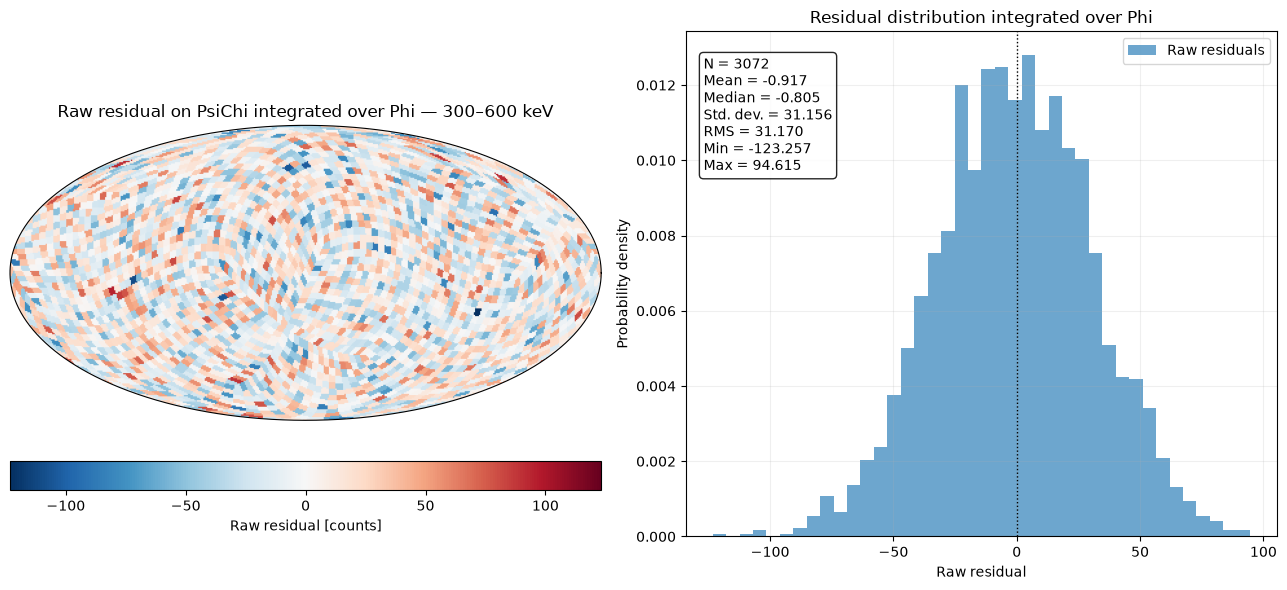

Selected interval: 300.0 to 600.0 keV
Aggregated Em edges: [300. 600.] keV
Aggregated Em bins: 1
Original Em bins remain: 3
Selected residual axes: ['Phi']


In [11]:
selected_range_analysis = full_analysis.select_energy_range(
    energy_min,
    energy_max,
)

# Calculate one standard angular residual for the selected interval.
selected_phi_residual = selected_range_analysis.residual_function(
    "Phi_projection",
    residual_type="raw",
)

# Initialize a plotter for the new selected-range analysis.
standard_range_plotter = PlottingResiduals(selected_range_analysis)
selected_phi_figure = standard_range_plotter.plot(
    "Phi_projection",
    residual_type="raw",
)

# Show the paired rectangular CDS residual maps for the integrated range.
selected_angular_2d_figure = standard_range_plotter.plot(
    "Phi_Chi_projection",
    residual_type="raw",
)

# Show the Phi-integrated PsiChi residual geometry for the range.
selected_psichi_figure = standard_range_plotter.plot(
    "PsiChi_projection",
    residual_type="raw",
)

# Verify that the returned object contains exactly the requested interval.
selected_edges_keV = (
    selected_range_analysis.observed_hist.axes["Em"].edges.to_value("keV")
)
if not np.allclose(selected_edges_keV, [energy_min, energy_max]):
    raise RuntimeError("The returned Em interval does not match the request.")

print("Selected interval:", energy_min, "to", energy_max, "keV")
print("Aggregated Em edges:", selected_range_analysis.observed_hist.axes["Em"].edges)
print("Aggregated Em bins:", selected_range_analysis.observed_hist.axes["Em"].nbins)
print("Original Em bins remain:", full_analysis.observed_hist.axes["Em"].nbins)
print("Selected residual axes:", selected_phi_residual.axes.labels)

### Selected-range workflow output

`selected_phi_residual` contains raw residuals for the interval defined by the chosen edge indices. The 1D plot summarizes its `Phi` dependence, the paired rectangular maps reveal joint `Phi-Chi` and `Phi-Psi` structure, and the HEALPix map preserves its Phi-integrated `PsiChi` geometry. These are **energy-integrated CDS diagnostics** because the selected original bins were summed before projection. In contrast, Workflow A retained `Em` in its energy-resolved products. The printed axes verify that the returned object has one `Em` bin while `full_analysis` remains unchanged.

<a id="part-ii"></a>

# PART II: API reference, customization, and advanced diagnostics

The remaining sections document the complete interface: lower-level projections, alternate residual definitions, plotting parameters, Pearson simulations, energy-sliced maps, statistical summaries, and energy-selection restrictions.

### Method reference

| Class | Method | Multi-energy role |
|---|---|---|
| `ResidualAnalysis` | `__init__()` | Validate inputs and preserve all original `Em` bins. |
| | `mask_function()` | Define valid bins shared by all projections and selections. |
| | `projection_function()` | Retain `Em` together with requested CDS coordinates. |
| | `split_psichi_function()` | Form `Em_Chi` and `Em_Psi` while retaining `Em`. |
| | `projected_data()` | Build and cache all energy-resolved projections. |
| | `residual_function()` | Calculate residuals after identical observed/expected projections. |
| | `select_energy_range()` | Aggregate an exact-edge interval into one `Em` bin in a new analysis. |
| | `statistics_table()` | Summarize full CDS after an interval has been aggregated. |
| | `pearson_poisson_reference()` | Simulate one energy-resolved Pearson reference. |
| | `prepare_pearson_poisson_references()` | Prepare several energy views from shared simulations. |
| `PlottingResiduals` | `__init__()` | Store analysis, simulation defaults, and an optional energy slice. |
| | `plot()` | Draw energy spectra, energy-coordinate maps, or an energy-sliced HEALPix map. |

<a id="using-your-own-data"></a>

## Using your own data

Replace the demonstration path and HDF5 object names with those from your analysis. Both objects must be HistPy `Histogram` instances containing finite, non-negative counts, with identical axes and shapes. `observed` holds measured counts and `expected` holds the fitted total expectation.

```python
# Replace these three values with your own file and object names.
residual_file = repo_root / "data" / "residual" / "your_products.hdf5"
observed_name = "observed"
expected_name = "total_expectation"

observed = Histogram.open(residual_file, name=observed_name)
expected = Histogram.open(residual_file, name=expected_name)

# Use a numeric value only if the producing workflow inserted a known floor.
expected_floor = None
full_analysis = ResidualAnalysis(
    observed, expected, expected_floor=expected_floor
)

energy_edges_keV = observed.axes["Em"].edges.to_value("keV")
print("Available Em edges [keV]:", energy_edges_keV)
```

Leave `expected_floor=None` unless the producing workflow deliberately inserted a known artificial floor; if it did, pass that exact value. Masking then excludes floor-level bins only when they contain no observed events. Before selecting a range, inspect `energy_edges_keV`: both limits passed to `select_energy_range()` must come from this array. The observed and expected object names may differ in another file, so inspect its HDF5 keys first.

### Analysis construction and masking

**Method: `ResidualAnalysis.__init__()`**

- **Purpose:** Validate matching observed and expected histograms, build the mask, and preserve all original `Em` bins.
- **Parameters:** `observed`, `expected`, and optional `expected_floor=None`.
- **Returns:** A `ResidualAnalysis` object. Initialization itself returns `None`.
- **Example:** Part I creates `full_analysis` without selecting or combining bins.
- **Customization:** Provide `expected_floor` only when the producing workflow deliberately inserted a known artificial expected-count floor; otherwise leave it as `None`. It is not a general low-count cut.
- **Notes:** Masked copies are created without modifying the originals; all projections and energy selections use those copies. Floor-level bins are excluded only when their observed counts are zero.

**Method: `mask_function()`**

- **Purpose:** Identify valid CDS bins and summarize exclusions in `mask_report`.
- **Parameters:** None; it uses the histograms and `expected_floor` stored by the constructor.
- **Returns:** A Boolean mask with the original CDS shape and a report dictionary.
- **Example:** The next cell verifies the stored mask and displays its report.
- **Customization:** Configure a known artificial floor through `expected_floor` during construction.
- **Notes:** Expected-floor bins are excluded only when their observed counts are zero. Observed events at the floor raise `ValueError` rather than being hidden.

In [12]:
# The constructor has already stored the same result on full_analysis.
valid_mask, mask_report = full_analysis.mask_function()
print("Stored and recalculated masks agree:", np.array_equal(valid_mask, full_analysis.mask))
display(mask_report)

Stored and recalculated masks agree: True


{'total_bins': 552960,
 'valid_bins': np.int64(552960),
 'excluded_bins': np.int64(0),
 'observed_counts_excluded': np.float64(0.0),
 'expected_floor': None,
 'minimum_expected': <Quantity 4.5e-13>,
 'minimum_retained_expected': <Quantity 4.5e-13>}

### Construct energy-resolved products directly

**Method: `projection_function()`**

- **Purpose:** Retain named axes and integrate omitted axes from the masked observed and expected counts.
- **Parameters:** `*axis_names`: one or more existing axis labels. Include `"Em"` to preserve energy.
- **Returns:** A dictionary containing matching `observed` and `expected` histograms.
- **Example:** The next cell retains `Em` and `PsiChi`.
- **Customization:** Use `"Em", "Phi"` for a direct energy-versus-`Phi` product.
- **Notes:** Omitting `Em` integrates energy, so the standard multi-energy interface intentionally includes it.

**Method: `split_psichi_function()`**

- **Purpose:** Convert `PsiChi` into separate `Chi` and `Psi` coordinates while retaining every other axis.
- **Parameters:** A product dictionary containing `PsiChi`, plus angular `bin_width=5.0` degrees.
- **Returns:** Here, `Em_Chi` and `Em_Psi` dictionaries containing observed and expected histograms.
- **Example:** The next cell splits the direct `Em_PsiChi` product.
- **Customization:** Change `bin_width` for a different rectangular sampling.
- **Notes:** The method checks count preservation and is normally called automatically by `projected_data()`.

In [13]:
# Preserve Em while projecting the remaining CDS dimensions to PsiChi.
em_psichi_products = full_analysis.projection_function("Em", "PsiChi")
em_split_products = full_analysis.split_psichi_function(em_psichi_products)

print("Direct projection axes:", em_psichi_products["observed"].axes.labels)
print("Split products:", tuple(em_split_products))
print("Em-Chi axes:", em_split_products["Em_Chi"]["observed"].axes.labels)
print("Em-Psi axes:", em_split_products["Em_Psi"]["observed"].axes.labels)

Direct projection axes: ['Em' 'PsiChi']
Split products: ('Em_Chi', 'Em_Psi')
Em-Chi axes: ['Em' 'Chi']
Em-Psi axes: ['Em' 'Psi']


<a id="projections-and-residuals"></a>

## Available energy-resolved projections

**Method: `projected_data()`**

- **Purpose:** Build and cache the supported energy-resolved projection set.
- **Parameters:** None.
- **Returns:** `Em_projection`, `Em_Phi_projection`, `Em_Chi_projection`, `Em_Psi_projection`, and `Em_PsiChi_projection`, each with observed and expected histograms.
- **Example:** The next cell prints the axes and shapes.
- **Customization:** Pass any returned ID to `residual_function()` or `plot()`.
- **Notes:** Every result preserves the original `Em` axis; repeated calls reuse the cache.

Use `full_analysis` directly when the goal is to study how residuals change with energy. Do not call `select_energy_range()` in this workflow.

`projected_data()` applies identical projections to the masked observed and expected histograms and retains `Em` in every result. The inspection cell below is optional: it shows the available histogram objects and shapes, but `PlottingResiduals` will call `projected_data()` internally when only figures are needed.

In [14]:
# Generate projections without integrating the Em dimension.
energy_resolved_products = full_analysis.projected_data()

for projection_name, products in energy_resolved_products.items():
    print(
        projection_name,
        "| axes:",
        products["observed"].axes.labels,
        "| shape:",
        products["observed"].shape,
    )

Em_projection | axes: ['Em'] | shape: (3,)
Em_Phi_projection | axes: ['Em' 'Phi'] | shape: (3, 60)
Em_Chi_projection | axes: ['Em' 'Chi'] | shape: (3, 72)
Em_Psi_projection | axes: ['Em' 'Psi'] | shape: (3, 36)
Em_PsiChi_projection | axes: ['Em' 'PsiChi'] | shape: (3, 3072)


### Calculate an energy-resolved residual directly

**Method: `residual_function()`**

- **Purpose:** Calculate raw, Pearson, or fractional residuals after the selected energy-resolved projection.
- **Parameters:** A projection ID returned above and `residual_type="raw"`, which also accepts `"pearson"` or `"fractional"`.
- **Returns:** A residual `Histogram` retaining the projection axes.
- **Example:** The next cell calculates the `Em-Phi` Pearson residual.
- **Customization:** Change the projection ID to another energy-resolved view.
- **Notes:** Normalized residuals are `NaN` where projected expectation is not positive. The plotter calls this method internally.

In [15]:
# Modify these two variables to retrieve another supported residual.
projection_id = "Em_Phi_projection"
residual_type = "pearson"

em_phi_residual = full_analysis.residual_function(
    projection_id, residual_type
)
print("Residual axes:", em_phi_residual.axes.labels)
print("Residual shape:", em_phi_residual.shape)
print("Finite residuals:", np.isfinite(em_phi_residual.contents).sum())

Residual axes: ['Em' 'Phi']
Residual shape: (3, 60)
Finite residuals: 180


<a id="poisson-monte-carlo"></a>

### Prepare energy-resolved Pearson references

**Method: `pearson_poisson_reference()`**

- **Purpose:** Simulate the reference Pearson-residual distribution for one energy projection.
- **Parameters:** Projection ID; `n_simulations=1000`; distribution `bins=15`; `seed=None`; and `energy_bin_index=None`, which is required for `Em_PsiChi_projection`. `phi_bin_index=None` is the analogous single-bin option.
- **Returns:** `bin_edges`, mean `density`, pointwise 95% `lower` and `upper` limits, and effective `seed`.
- **Example:** The next cell prepares `Em_Phi_projection`.
- **Customization:** Increase the simulation count for a smoother final reference.
- **Notes:** `n_simulations` must be an integer of at least 2 and `bins` a positive integer. The fixed expectation is not refitted, so this is not a goodness-of-fit test.

**Method: `prepare_pearson_poisson_references()`**

- **Purpose:** Reuse each full-CDS simulation across several energy-resolved projections.
- **Parameters:** `projection_bins`; `n_simulations=1000`; `seed=None`; `phi_bin_indices=None`; and `energy_bin_indices=None` for sliced projections.
- **Returns:** References keyed by `(projection_id, slice_index)`.
- **Example:** The second call below shares simulations between `Em_projection`, `Em_Chi_projection`, and one HEALPix energy slice.
- **Customization:** Common choices are 15 distribution bins for `Em_projection` and 40 for maps.
- **Notes:** Results are cached; use this method when preparing several figures. Slice-index mappings are accepted only for their corresponding sliced HEALPix projection.

In [16]:
# Keep this tutorial quick; increase the count for final diagnostics.
em_phi_reference = full_analysis.pearson_poisson_reference(
    "Em_Phi_projection", n_simulations=50, bins=40, seed=42
)
shared_energy_references = full_analysis.prepare_pearson_poisson_references(
    {"Em_projection": 15, "Em_Chi_projection": 40, "Em_PsiChi_projection": 40},
    n_simulations=50,
    seed=42,
    energy_bin_indices={"Em_PsiChi_projection": 0},
)
print("Single-reference fields:", tuple(em_phi_reference))
print("Shared-reference keys:", tuple(shared_energy_references))

Single-reference fields: ('bin_edges', 'density', 'lower', 'upper', 'seed')
Shared-reference keys: (('Em_projection', None), ('Em_Chi_projection', None), ('Em_PsiChi_projection', 0))


<a id="plotting-customization"></a>

### Plot energy-resolved residuals

**Method: `PlottingResiduals.__init__()`**

- **Purpose:** Store the analysis plus reusable simulation and slice defaults.
- **Parameters:** `analysis`; `n_simulations=None`; `random_seed=None`; `phi_bin_index=None`; and `energy_bin_index=None`.
- **Returns:** A plotting object. Initialization itself returns `None`.
- **Example:** The next cell creates `energy_resolved_plotter`.
- **Customization:** Set `energy_bin_index` here as a default or pass it to an individual `plot()` call.
- **Notes:** The plotting object reads products from the analysis; it does not consume the direct residual variable above.

**Method: `plot()`**

- **Purpose:** Route each projection to its supported layout and display the diagnostic.
- **Parameters:** `projection_id`; `residual_type="raw"`; `phi_bin_index=None`; `running_mean_window=None`; `n_simulations=None`; `random_seed=None`; `show_gaussian_reference=None`; and `energy_bin_index=None`.
- **Returns:** A Matplotlib `Figure`.
- **Example:** The next cells show `Em_projection`, `Em_Chi_projection`, and a sliced `Em_PsiChi_projection`.
- **Customization:** Replace `Em_Chi_projection` with `Em_Phi_projection` or `Em_Psi_projection`; the layout and arguments are identical.
- **Notes:** `energy_bin_index` selects a map for display but does not aggregate or modify energy bins.

`PlottingResiduals` needs only the full multi-energy `ResidualAnalysis` object. The projected-products variable above is not a required plotting input. `n_simulations` enables fixed-fit Poisson reference distributions for Pearson residuals, and `random_seed` makes those simulations reproducible. Increase `n_simulations` for a smoother final reference.

Three distinct plot families are demonstrated below: an energy spectrum, a rectangular energy-versus-coordinate map, and an energy-resolved HEALPix map.

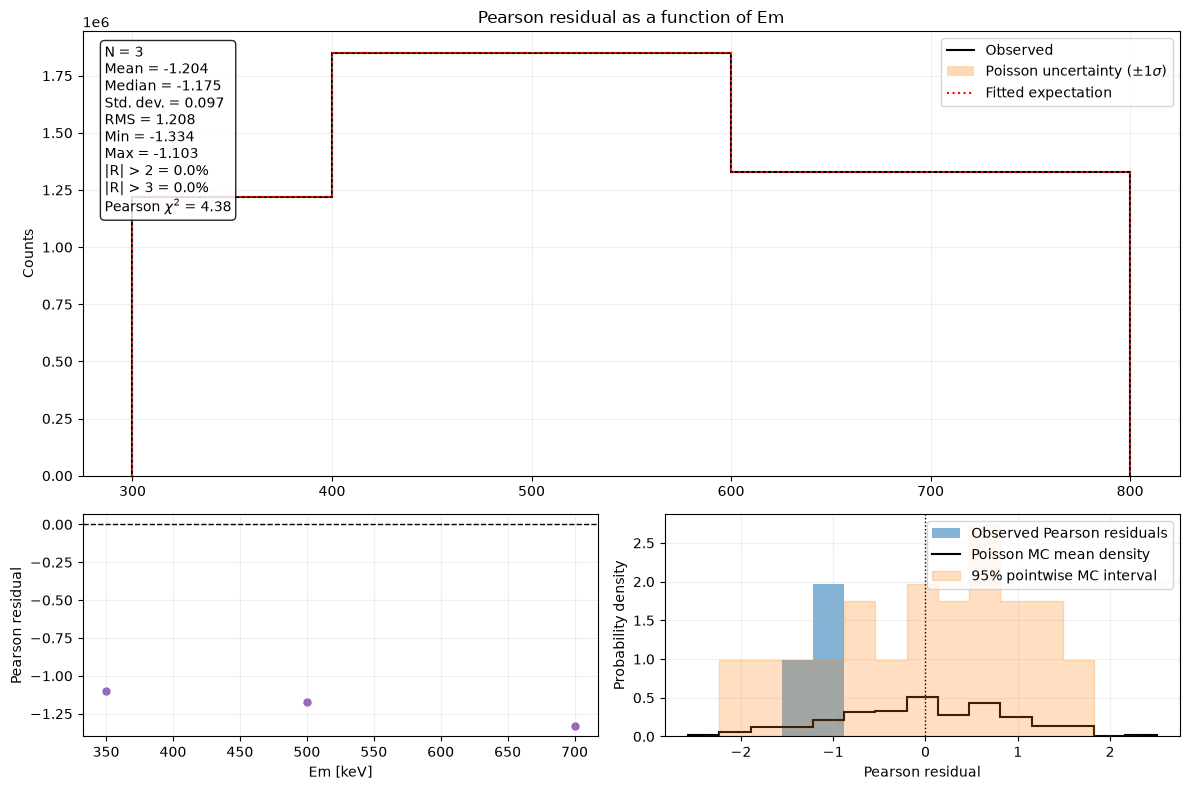

In [17]:
# Modify these values to control Monte Carlo cost and reproducibility.
n_simulations = 50
random_seed = 42

# Configure the plotter once and reuse it for this analysis object.
energy_resolved_plotter = PlottingResiduals(
    full_analysis,
    n_simulations=n_simulations,
    random_seed=random_seed,
)

# Em_projection integrates CDS coordinates but preserves every Em bin.
em_figure = energy_resolved_plotter.plot(
    "Em_projection",
    residual_type="pearson",
    show_gaussian_reference=False,
)

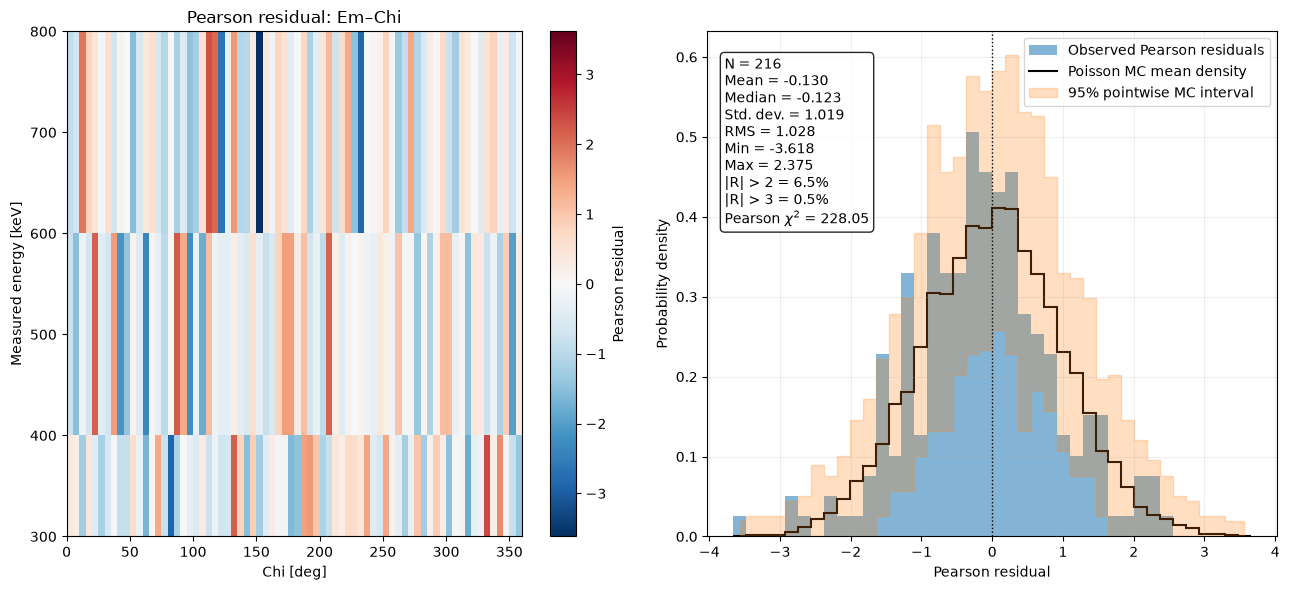

In [18]:
# Em_Chi_projection displays residuals versus energy and Chi.
# Replace it with Em_Phi_projection or Em_Psi_projection for those views.
em_chi_figure = energy_resolved_plotter.plot(
    "Em_Chi_projection",
    residual_type="pearson",
    show_gaussian_reference=False,
)

### Select a map from `Em_PsiChi_projection`

`Em_PsiChi_projection` contains one HEALPix map for every original `Em` bin. A two-dimensional sky map can display only one at a time, so `plot()` requires a zero-based `energy_bin_index`. Valid indices run from `0` through `full_analysis.observed_hist.axes["Em"].nbins - 1`.

Inspect the printed edge list to associate each index with its energy interval, then modify only `energy_bin_index`. This selects only the displayed slice; it does not remove bins, integrate energy, or modify `full_analysis`.

Valid energy_bin_index range: 0 to 2
Displayed energy interval: 300.0 keV to 400.0 keV


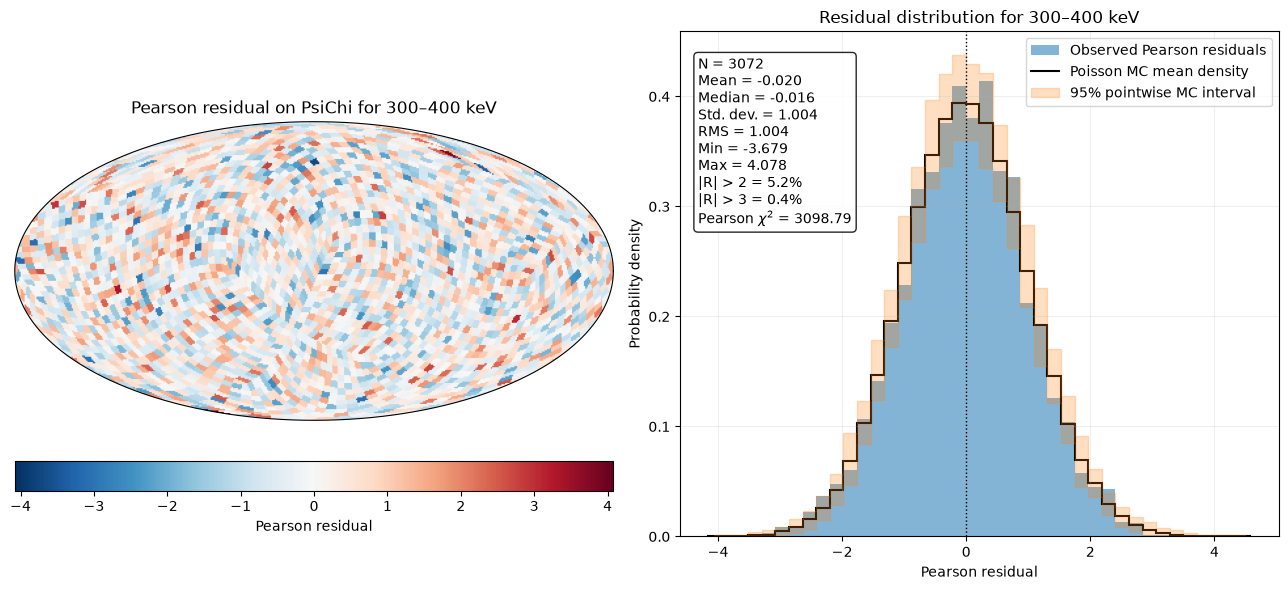

In [19]:
# Inspect the valid range and select which original Em-bin map to display.
print("Valid energy_bin_index range: 0 to", energy_bin_count - 1)

# Modify this variable to display another original energy bin.
energy_bin_index = 0

print(
    "Displayed energy interval:",
    energy_edges[energy_bin_index],
    "to",
    energy_edges[energy_bin_index + 1],
)

em_psichi_figure = energy_resolved_plotter.plot(
    "Em_PsiChi_projection",
    residual_type="pearson",
    energy_bin_index=energy_bin_index,
    show_gaussian_reference=False,
)

A global `statistics_table()` is intentionally unavailable for `full_analysis` because it still contains multiple `Em` bins. The projection plots provide energy-resolved diagnostics. To obtain one full-CDS table, first select and aggregate an interval as shown next.

## Energy-range selection details

**Method: `select_energy_range()`**

- **Purpose:** Select the same original energy bins in observed and expected data, sum them over `Em`, and create a standard one-bin analysis.
- **Parameters:** `energy_min` and `energy_max` in keV. Both must match printed `Em` edges, and the minimum must be lower.
- **Returns:** A new `ResidualAnalysis` with a length-one `Em` axis spanning the requested interval.
- **Example:** Part I chooses `lower_edge_index=0` and `upper_edge_index=2`, derives the corresponding energies from `energy_edges_keV`, and then inspects both analysis objects.
- **Customization:** Change only those two edge-index variables. Adjacent edge indices select one original bin; non-adjacent indices aggregate every bin between them.
- **Notes:** Selection starts from the already masked histograms. The original multi-energy object remains unchanged. Invalid edges raise a `ValueError` listing the available edges.

Use `select_energy_range(energy_min, energy_max)` when the scientific question concerns one integrated interval. Both limits are specified in keV and must match existing `Em` edges exactly.

Adjacent edges select one original bin. Wider limits select multiple bins, which are summed over `Em` before residuals are calculated. The same selection and aggregation are applied to the masked observed and expected counts.

In [20]:
# The valid boundaries are the existing edges printed in Part I.
# Reuse the selected-range object already created in the practical workflow.
print("Selected interval:", energy_min, "to", energy_max, "keV")
print(
    "Aggregated Em edges:",
    selected_range_analysis.observed_hist.axes["Em"].edges,
)
print("Aggregated shape:", selected_range_analysis.observed_hist.shape)
print("Original shape remains:", full_analysis.observed_hist.shape)

Selected interval: 300.0 to 600.0 keV
Aggregated Em edges: [300. 600.] keV
Aggregated shape: (1, 60, 3072)
Original shape remains: (3, 60, 3072)


### Use the standard CDS interface after aggregation

The selected-range object contains one aggregated `Em` bin. It therefore supports the same projection IDs, residual definitions, plot families, and statistics table as a file that originally contained one bin. A new plotter is required because this is a new `ResidualAnalysis` object.

The advanced example below combines several configurable options without repeating every possible plot. `running_mean_window=5` is valid only for a 1D Pearson plot. `show_gaussian_reference=True` explicitly shows the standard-normal curve; with the default `None`, it appears when simulations are off and is hidden when they are on. Set it to `False` to suppress the curve. The final call derives a valid `phi_bin_index` from the selected-range `Phi` axis and displays the corresponding `Phi_PsiChi_projection` slice.

In [21]:
# Confirm that the selected range now exposes standard CDS projections.
selected_range_products = selected_range_analysis.projected_data()

print("Available selected-range projections:")
for projection_name in selected_range_products:
    print("-", projection_name)

Available selected-range projections:
- Phi_projection
- Chi_projection
- Psi_projection
- PsiChi_projection
- Phi_Chi_projection
- Phi_Psi_projection
- Phi_PsiChi_projection
- Em_projection


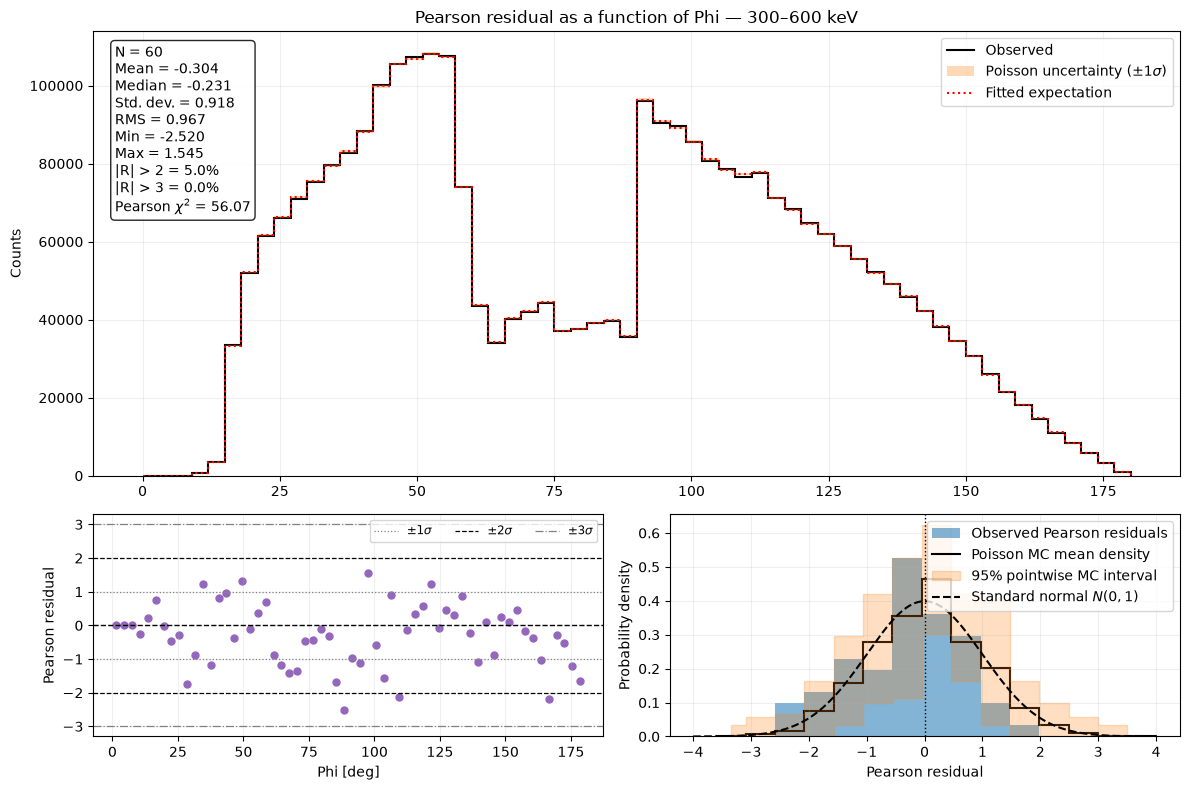

/Users/maura/Documents/COSI/data-challenge-4/workflow/src/plot_residuals.py:1086: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout()


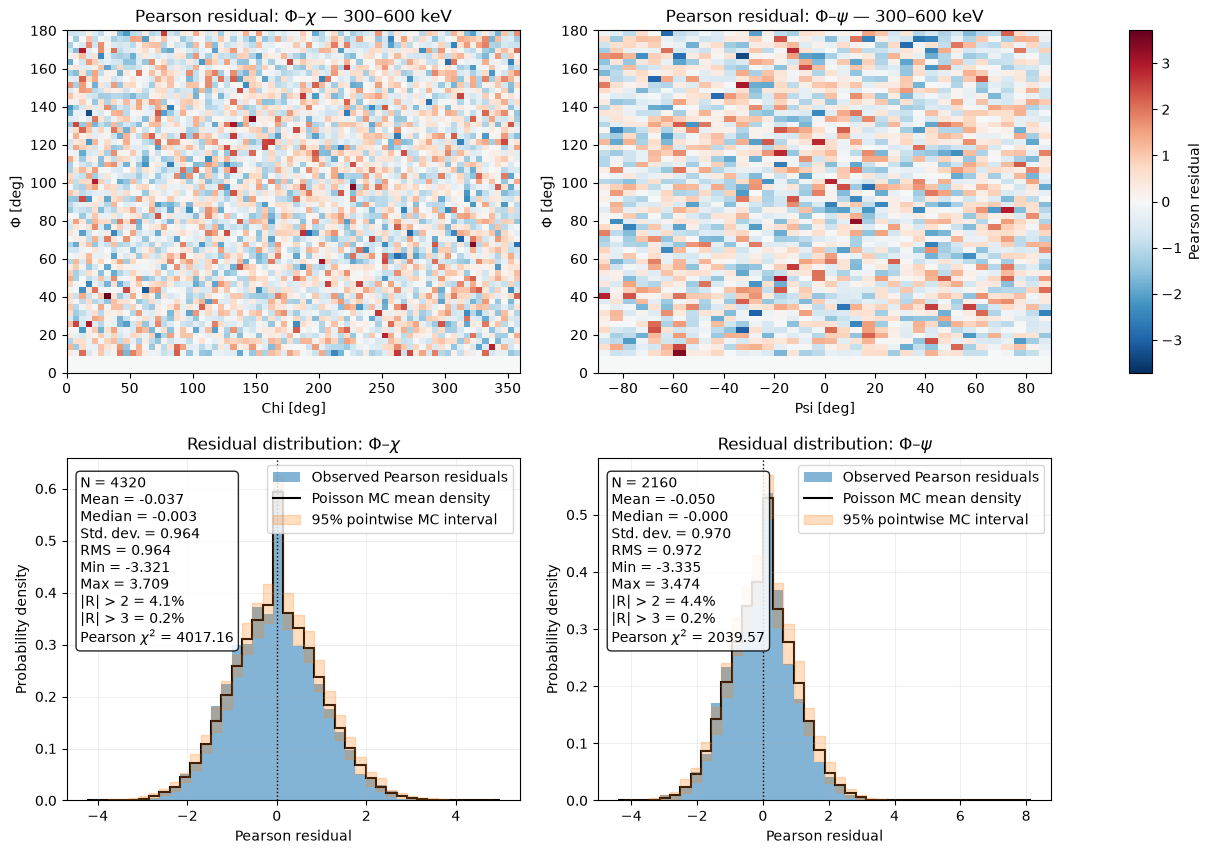

Valid phi_bin_index range: 0 to 59


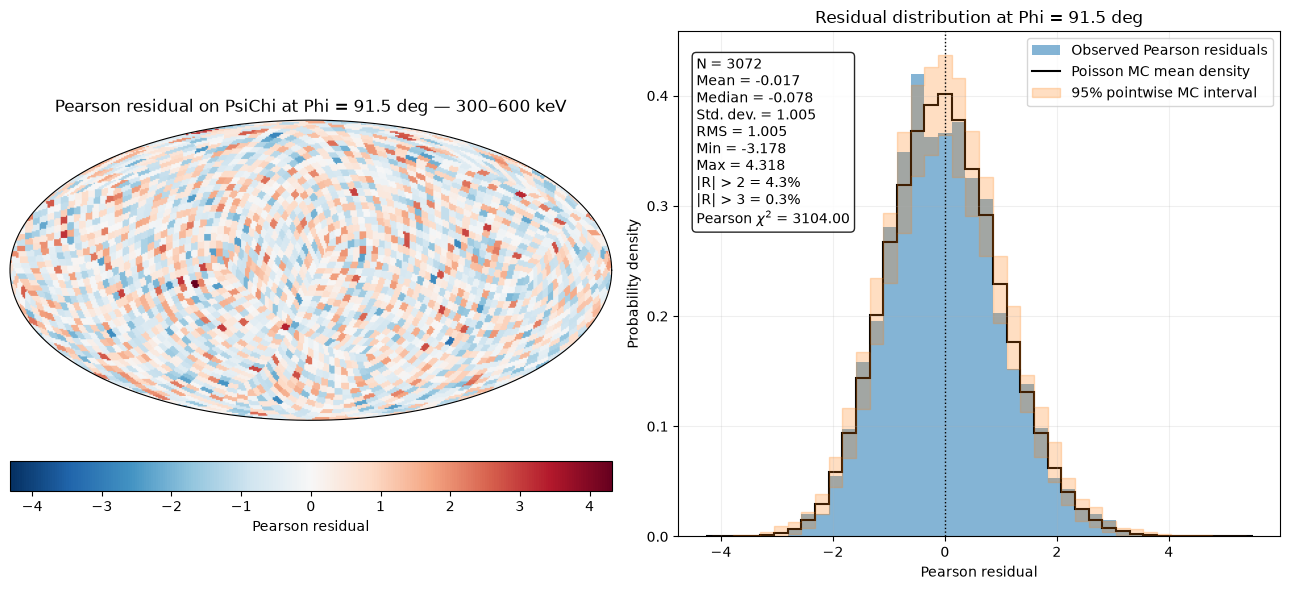

In [24]:
# Generate reproducible Poisson references from the aggregated expectation.
selected_n_simulations = 50
selected_random_seed = 42
selected_range_plotter = PlottingResiduals(
    selected_range_analysis,
    n_simulations=selected_n_simulations,
    random_seed=selected_random_seed,
)

# Demonstrate a centered running mean and an explicit Gaussian reference.
selected_range_phi_figure = selected_range_plotter.plot(
    "Phi_projection",
    residual_type="pearson",
    show_gaussian_reference=True,
)

# Either rectangular ID displays the paired Phi-Chi and Phi-Psi figure.
selected_range_2d_figure = selected_range_plotter.plot(
    "Phi_Psi_projection",
    residual_type="pearson",
    show_gaussian_reference=False,
)

# Inspect the valid Phi range and modify this variable for another slice.
selected_phi_axis = selected_range_analysis.observed_hist.axes["Phi"]
print("Valid phi_bin_index range: 0 to", selected_phi_axis.nbins - 1)
phi_bin_index = selected_phi_axis.nbins // 2
selected_range_healpix_figure = selected_range_plotter.plot(
    "Phi_PsiChi_projection",
    residual_type="pearson",
    phi_bin_index=phi_bin_index,
    show_gaussian_reference=False,
)

<a id="statistical-diagnostics"></a>

### Display the statistics table

**Method: `statistics_table()`**

- **Purpose:** Summarize residuals across valid full-CDS bins after the interval is aggregated.
- **Parameters:** `"raw"`, `"pearson"`, or `"fractional"`.
- **Returns:** A one-row pandas `DataFrame`; Pearson includes threshold fractions, chi-square, and Poisson deviance.
- **Example:** The next cell displays the selected-range Pearson summary.
- **Customization:** Change the residual type for the other summaries.
- **Notes:** It is intentionally unavailable on `full_analysis` while multiple `Em` bins remain. The table is descriptive and does not include fitted degrees of freedom or a goodness-of-fit probability.

In [23]:
# Use "raw" or "fractional" for the other residual definitions.
display(selected_range_analysis.statistics_table("pearson"))

,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,184320,-0.004631,-0.066489,0.975073,0.975084,-3.641611,11.526978,4.166667,0.520291,175249.352805,171014.691196


## Plotting helper responsibilities

These private methods explain the routing behavior but should not be called directly; use `plot()`.

| Private helper | Responsibility |
|---|---|
| `_plot_1d_projection()` | Draws `Em_projection` counts, residuals, and the optional normalized-residual distribution. |
| `_plot_energy_coordinate_projection()` | Draws `Em-Phi`, `Em-Chi`, or `Em-Psi` as a rectangular energy-coordinate map, plus a distribution for normalized residuals. |
| `_plot_psichi_projection()` | Selects one zero-based `energy_bin_index` and draws its `Em_PsiChi` HEALPix map and distribution. |
| `_prepare_pearson_references()` | Prepares and caches applicable references for the selected plotting configuration. |
| `_format_residual_statistics()` | Formats the statistics annotation used by normalized-residual plots. |

## Projection and option reference

### Multi-energy projections from `full_analysis`

| Projection ID | Retained axes | Histogram dimensionality | Energy mode | Visualization produced by `plot()` |
|---|---|---:|---|---|
| `Em_projection` | `Em` | 1D | All original bins retained | 1D energy counts and residual diagnostic |
| `Em_Phi_projection` | `Em`, `Phi` | 2D | All original bins retained | Rectangular energy-versus-`Phi` map |
| `Em_Chi_projection` | `Em`, `Chi` | 2D | All original bins retained | Rectangular energy-versus-`Chi` map |
| `Em_Psi_projection` | `Em`, `Psi` | 2D | All original bins retained | Rectangular energy-versus-`Psi` map |
| `Em_PsiChi_projection` | `Em`, `PsiChi` | 2D (`Em` plus HEALPix) | All original bins retained | HEALPix map for one `energy_bin_index` |

### Angular projections from `selected_range_analysis`

| Projection ID | Retained axes | Histogram dimensionality | Energy mode | Visualization produced by `plot()` |
|---|---|---:|---|---|
| `Em_projection` | Aggregated `Em` | 1D | Selected bins summed into one | 1D counts and residual diagnostic |
| `Phi_projection` | `Phi` | 1D | Selected bins summed before projection | 1D angular diagnostic |
| `Chi_projection` | `Chi` | 1D | Selected bins summed before projection | 1D angular diagnostic |
| `Psi_projection` | `Psi` | 1D | Selected bins summed before projection | 1D angular diagnostic |
| `PsiChi_projection` | `PsiChi` | 1D HEALPix axis | Selected bins summed before projection | Phi-integrated HEALPix map |
| `Phi_Chi_projection` | `Phi`, `Chi` | 2D | Selected bins summed before projection | Paired `Phi-Chi` and `Phi-Psi` maps |
| `Phi_Psi_projection` | `Phi`, `Psi` | 2D | Selected bins summed before projection | Same paired rectangular figure |
| `Phi_PsiChi_projection` | `Phi`, `PsiChi` | 2D (`Phi` plus HEALPix) | Selected bins summed before projection | HEALPix map for one `phi_bin_index` |

### Configurable plotting options

| Option | Default | Applies to |
|---|---|---|
| `residual_type` | `"raw"` | Every projection; also accepts `"pearson"` and `"fractional"` |
| `energy_bin_index` | `None` | Required for `Em_PsiChi_projection`; zero-based |
| `phi_bin_index` | `None` | Required for selected-range `Phi_PsiChi_projection`; zero-based |
| `running_mean_window` | `None` | Positive integer for 1D Pearson plots only |
| `n_simulations` | Constructor value or `None` | Fixed-fit Poisson references for Pearson plots only |
| `random_seed` | Constructor value or `None` | Reproducible Poisson simulations |
| `show_gaussian_reference` | Automatic | Pearson only; shown without Monte Carlo and hidden when Monte Carlo is enabled |

Passing Pearson-only options to raw or fractional plots raises `ValueError`. `energy_bin_index` chooses only a displayed map; it does not select or aggregate an analysis interval.